# Base Modeling (por máquina, ventana de 24 h → predicción a 24 h)

Este notebook parte del **dataset final** de Data Preparation (`dataset_final_serie_tiempo.parquet`).

Cambios principales respecto a la versión anterior:
- Las ventanas se construyen **por máquina** (antes mezclaban filas de distintas máquinas).
- Cada máquina se completa a una **grilla regular de 30 min**, de modo que 48 filas = 24 h reales.
- El split train/val/test se hace por **fecha de corte** (igual para todas las máquinas).
- El scaler/imputer se ajusta **solo con train**.
- Se evalúa **por máquina** y las rachas de cola se miden por máquina.

### 1. Conectar con Google Drive e importar librerías

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

IN_COLAB = "google.colab" in sys.modules

In [2]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\lstm\..\..\..\data


In [3]:
if IN_COLAB:
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [4]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [5]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

- `WINDOW = 48` bloques de 30 min = **24 h de historia** por máquina.
- `HORIZON = 48` bloques de 30 min = **24 h hacia adelante**.
- `MODO_OBJETIVO`:
  - `"punto"`: ¿habrá cola exactamente 24 h después del final de la ventana?
  - `"cualquiera"`: ¿habrá cola en **algún** bloque de las siguientes 24 h?

In [6]:
TARGET = "pct_posible_cola"
UMBRAL_COLA = 0.5
FREQ = "30min"
WINDOW = 48
HORIZON = 48
MODO_OBJETIVO = "punto"   # "punto" | "cualquiera"
FRAC_TRAIN, FRAC_VAL = 0.70, 0.85

# Preparación por máquina

1. Cada máquina se reindexa a una grilla completa de 30 min (los huecos quedan como NaN y se marcan con `observado = 0`).
2. Se define la etiqueta `cola`; donde no hay dato, la etiqueta es NaN (esas ventanas se descartan).

In [7]:
df_raw = load_dataset()

def completar_grilla(df, freq):
    partes = []
    for ms, g in df.groupby("ms", sort=False):
        g = g.drop_duplicates("bloque_tiempo").set_index("bloque_tiempo").sort_index()
        grilla = pd.date_range(g.index.min(), g.index.max(), freq=freq)
        originales = g.index
        g = g.reindex(grilla)
        g["observado"] = g.index.isin(originales).astype("float32")
        g["ms"] = ms
        if "temporada" in g.columns:
            g["temporada"] = g["temporada"].ffill().bfill()
        g.index.name = "bloque_tiempo"
        partes.append(g.reset_index())
    return pd.concat(partes, ignore_index=True)

n_antes = len(df_raw)
full = completar_grilla(df_raw, FREQ)
print(f"Filas originales: {n_antes:,} | tras completar grilla: {len(full):,} "
      f"({len(full) - n_antes:,} huecos rellenados con NaN)")
print("Máquinas:", full["ms"].nunique())

# Etiqueta: NaN si no hay dato del target en ese bloque
full["cola"] = np.where(full[TARGET].notna(), (full[TARGET] > UMBRAL_COLA).astype("float32"), np.nan)

# Metadatos (antes de pasar ms a dummies)
meta = full[["bloque_tiempo", "ms"]].copy()
y_full = full["cola"].values.astype("float32")          # con NaN donde no hay dato
full["cola"] = full["cola"].fillna(0).astype("float32")  # como feature, el hueco cuenta como 0

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']
Filas originales: 179,850 | tras completar grilla: 179,850 (0 huecos rellenados con NaN)
Máquinas: 3


# Normalización de datos

El preprocesador se ajusta **únicamente con filas de train** (anterior a la fecha de corte) y se aplica al resto.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Fechas de corte comunes a todas las máquinas
tiempos = np.sort(full["bloque_tiempo"].unique())
corte_train = tiempos[int(len(tiempos) * FRAC_TRAIN)]
corte_val = tiempos[int(len(tiempos) * FRAC_VAL)]
print("Corte train/val :", corte_train)
print("Corte val/test  :", corte_val)

X_df = pd.get_dummies(full.drop(columns=["bloque_tiempo"]),
                      columns=[c for c in ["ms", "temporada"] if c in full.columns],
                      dtype="float32")

dummies = [c for c in X_df.columns if c.startswith(("ms_", "temporada_"))]
binarias = dummies + ["cola", "observado"]
categoricas = X_df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numericas = [c for c in X_df.select_dtypes(include="number").columns
             if c not in binarias]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

# Ajuste solo con train (filas observadas anteriores al corte)
mask_fit = ((meta["bloque_tiempo"] < corte_train) & (full["observado"] == 1)).values
preprocessor.fit(X_df[mask_fit])

X_norm = preprocessor.transform(X_df)
feature_names = list(X_norm.columns)
X_all = X_norm.astype("float32").values
print("X_all:", X_all.shape, "| features:", len(feature_names))

Corte train/val : 2024-12-22T07:00:00.000000000
Corte val/test  : 2025-06-27T15:30:00.000000000
X_all: (179850, 30) | features: 30


# Ventanas por máquina y separación train / val / test

Cada ventana usa 48 bloques consecutivos **de una sola máquina** (24 h) y predice 24 h hacia adelante.
El split se asigna según la **fecha del bloque objetivo**, así no hay ventanas que mezclen máquinas
ni objetivos que caigan en otro periodo.

In [9]:
def ventanas_maquina(X_m, y_m, t_m, window, horizon, modo):
    T = len(X_m)
    n_w = T - window - horizon + 1
    if n_w <= 0:
        return None
    # (n, F, window) -> (n, window, F)
    Xw = sliding_window_view(X_m, window, axis=0)[:n_w].transpose(0, 2, 1)
    ini = window - 1 + horizon          # índice del bloque objetivo (modo punto) / último del horizonte
    if modo == "punto":
        y_t = y_m[ini: ini + n_w]
    elif modo == "cualquiera":
        ysw = sliding_window_view(y_m, horizon)          # (T-h+1, h)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            y_t = np.nanmax(ysw[window: window + n_w], axis=1)
    else:
        raise ValueError("MODO_OBJETIVO debe ser 'punto' o 'cualquiera'")
    t_t = t_m[ini: ini + n_w]
    ok = ~np.isnan(y_t)
    return Xw[ok], y_t[ok].astype("float32"), t_t[ok]

Xs, ys, ts, mss = [], [], [], []
for ms, idx in meta.groupby("ms").indices.items():
    idx = np.sort(idx)
    res = ventanas_maquina(X_all[idx], y_full[idx], meta["bloque_tiempo"].values[idx],
                           WINDOW, HORIZON, MODO_OBJETIVO)
    if res is None:
        print(f"Máquina {ms}: muy corta, se omite")
        continue
    Xw_m, yw_m, tw_m = res
    Xs.append(Xw_m); ys.append(yw_m); ts.append(tw_m); mss.append(np.full(len(yw_m), ms, dtype=object))

Xw = np.concatenate(Xs)
yw = np.concatenate(ys)
t_obj = np.concatenate(ts)
ms_obj = np.concatenate(mss)

# Orden cronológico global (estable por máquina)
orden = np.lexsort((ms_obj.astype(str), t_obj))
Xw, yw, t_obj, ms_obj = Xw[orden], yw[orden], t_obj[orden], ms_obj[orden]

train = t_obj < corte_train
val = (t_obj >= corte_train) & (t_obj < corte_val)
test = t_obj >= corte_val

X_train, y_train = Xw[train], yw[train]
X_val, y_val = Xw[val], yw[val]
X_test, y_test = Xw[test], yw[test]
meta_test = pd.DataFrame({"ms": ms_obj[test], "bloque_tiempo": t_obj[test]})

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

print("\n=== RANGOS DE FECHAS DEL BLOQUE OBJETIVO ===")
for nombre, mascara in {"Train": train, "Val": val, "Test": test}.items():
    print(f"{nombre:<6} | Inicio: {t_obj[mascara].min()} | Fin: {t_obj[mascara].max()} | Ventanas: {mascara.sum():,}")

X_train: (125607, 48, 30) | X_val: (26979, 48, 30) | X_test: (26979, 48, 30)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575

=== RANGOS DE FECHAS DEL BLOQUE OBJETIVO ===
Train  | Inicio: 2022-08-02T23:30:00.000000000 | Fin: 2024-12-22T06:30:00.000000000 | Ventanas: 125,607
Val    | Inicio: 2024-12-22T07:00:00.000000000 | Fin: 2025-06-27T15:00:00.000000000 | Ventanas: 26,979
Test   | Inicio: 2025-06-27T15:30:00.000000000 | Fin: 2025-12-31T23:30:00.000000000 | Ventanas: 26,979


# Entrenamiento de las arquitecturas

In [42]:
model_path = Path.cwd().parent.parent.parent

model_output_dir = model_path / "models" / "lstm"
model_output_dir.mkdir(parents=True, exist_ok=True)

print(model_output_dir)

c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\models\lstm


In [ ]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lstm_model import LSTMModel
else:
  from lstm_model import LSTMModel

import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping

model_base = LSTMModel()


architectures = ("base", "dense", "norm", "norm+drop")

class_labels = np.unique(y_train.astype(int))
if not np.array_equal(class_labels, np.array([0, 1])):
    raise ValueError("El conjunto de entrenamiento debe contener ambas clases.")

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=y_train.astype(int),
)
class_weight = dict(zip(class_labels, class_weights))
training_results = {}

In [27]:
for architecture in architectures:
    tf.keras.utils.set_random_seed(42)
    model = model_base.compile(
        input_shape=X_train.shape[1:],
        v=architecture,
    )
    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
        )
    ]
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=128,
        class_weight=class_weight,
        callbacks=callbacks,
        shuffle=True,   # válido: cada ventana ya es una muestra independiente con su propia historia
        verbose=1,
    )
    validation_probabilities = model.predict(X_val, verbose=0).ravel()
    training_results[architecture] = {
        "model": model,
        "history": history,
        "validation_probabilities": validation_probabilities,
    }

Epoch 1/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 119s 118ms/step - accuracy: 0.6626 - auc: 0.7396 - loss: 0.6005 - precision: 0.2632 - recall: 0.7213 - val_accuracy: 0.4892 - val_auc: 0.6413 - val_loss: 0.8475 - val_precision: 0.4539 - val_recall: 0.9886
Epoch 2/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 117s 119ms/step - accuracy: 0.6737 - auc: 0.7527 - loss: 0.5884 - precision: 0.2716 - recall: 0.7271 - val_accuracy: 0.4875 - val_auc: 0.6403 - val_loss: 0.8618 - val_precision: 0.4532 - val_recall: 0.9934
Epoch 3/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 110s 111ms/step - accuracy: 0.6760 - auc: 0.7579 - loss: 0.5834 - precision: 0.2739 - recall: 0.7308 - val_accuracy: 0.4849 - val_auc: 0.6381 - val_loss: 0.8644 - val_precision: 0.4520 - val_recall: 0.9935
Epoch 4/50
982/982 ━━━━━━━━━━━━━━━━━━━━ 112s 114ms/step - accuracy: 0.6747 - auc: 0.7608 - loss: 0.5803 - precision: 0.2742 - recall: 0.7382 - val_accuracy: 0.4934 - val_auc: 0.6341 - val_loss: 0.8521 - val_precision: 0.4560 - val_recall: 0.9902
Epoch 5/50
982/9

# Selección de umbral y arquitectura (validación)

In [28]:
from sklearn.metrics import precision_recall_curve

validation_comparison = []
for architecture, result in training_results.items():
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        result["validation_probabilities"],
    )
    if thresholds.size == 0:
        raise ValueError(
            f"No se pudieron calcular umbrales para {architecture}."
        )
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )
    best_idx = int(np.argmax(f1_scores))
    result["threshold"] = float(thresholds[best_idx])
    result["validation_precision"] = float(precision[best_idx])
    result["validation_recall"] = float(recall[best_idx])
    result["validation_f1"] = float(f1_scores[best_idx])
    validation_comparison.append(
        {
            "Architecture": architecture,
            "Threshold": result["threshold"],
            "Validation Precision": result["validation_precision"],
            "Validation Recall": result["validation_recall"],
            "Validation F1": result["validation_f1"],
        }
    )

validation_comparison = pd.DataFrame(validation_comparison).sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)
display(validation_comparison)

,Architecture,Threshold,Validation Precision,Validation Recall,Validation F1
0,base,0.660110,0.476535,0.947630,0.634166
1,norm,0.676426,0.483296,0.911380,0.631639
2,dense,0.673992,0.478382,0.925584,0.630760
3,norm+drop,0.650451,0.471440,0.950767,0.630329


# Evaluación en test


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.657474
Precision 0.632159
   Recall 0.967788
 F1-Score 0.764770
  ROC-AUC 0.665267
   PR-AUC 0.684835


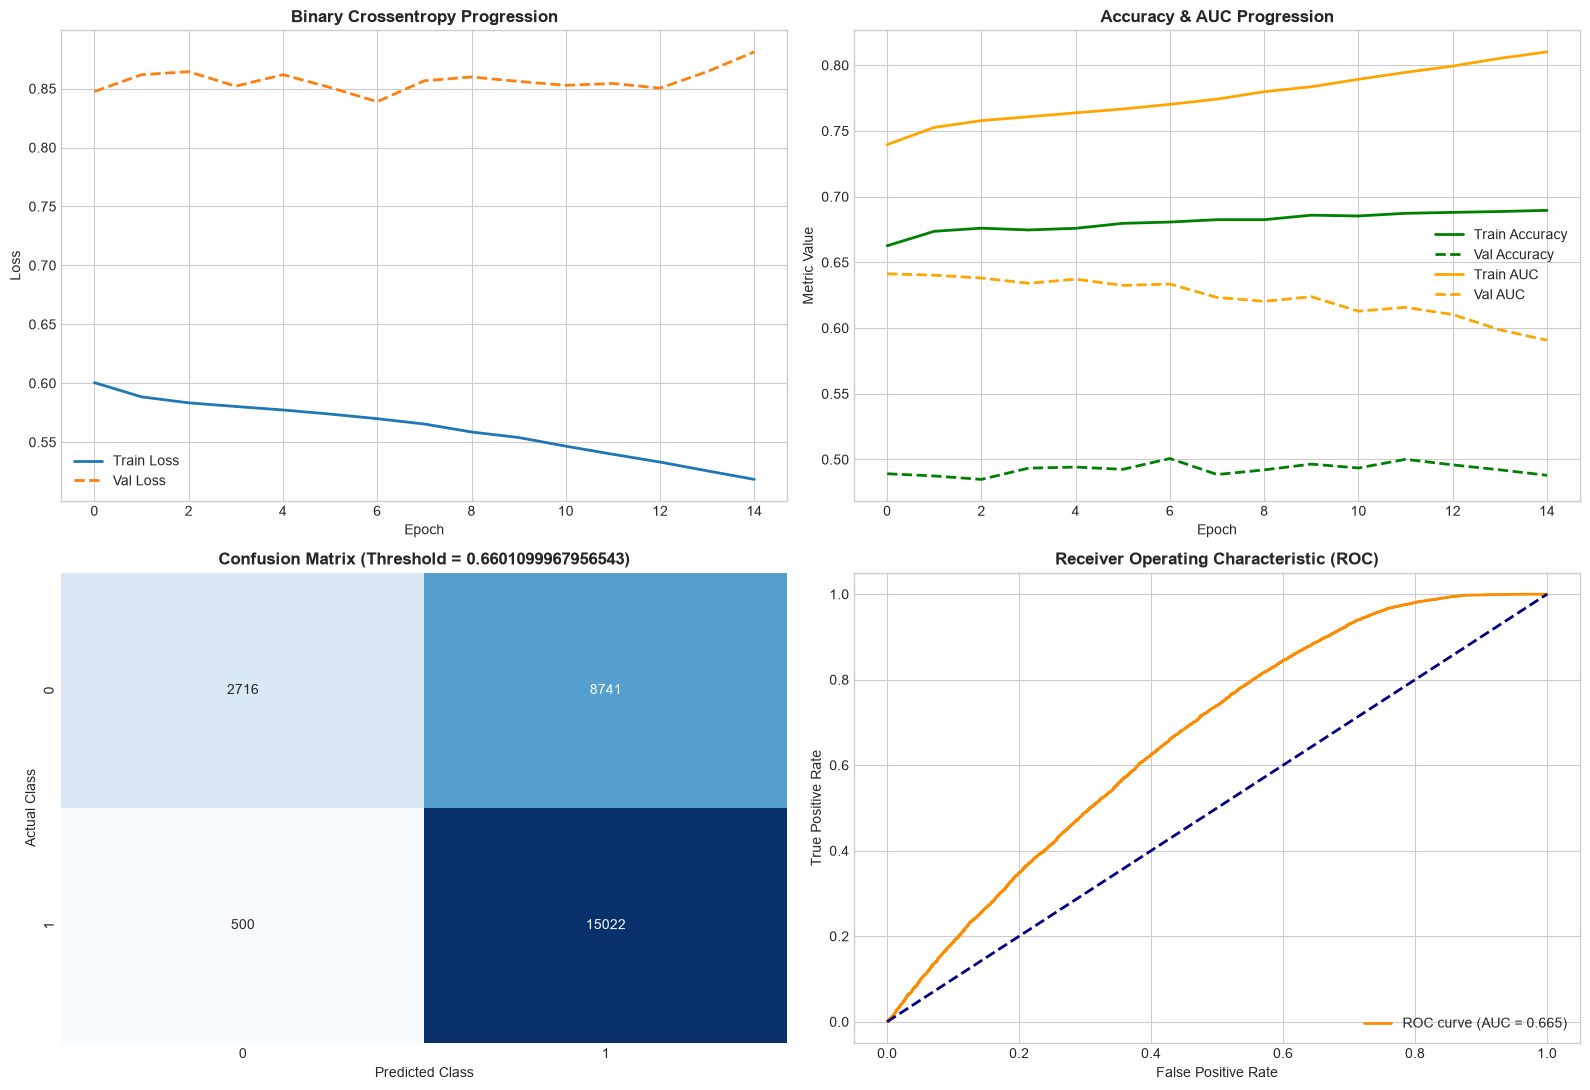


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.652396
Precision 0.628924
   Recall 0.965468
 F1-Score 0.761677
  ROC-AUC 0.675038
   PR-AUC 0.700726


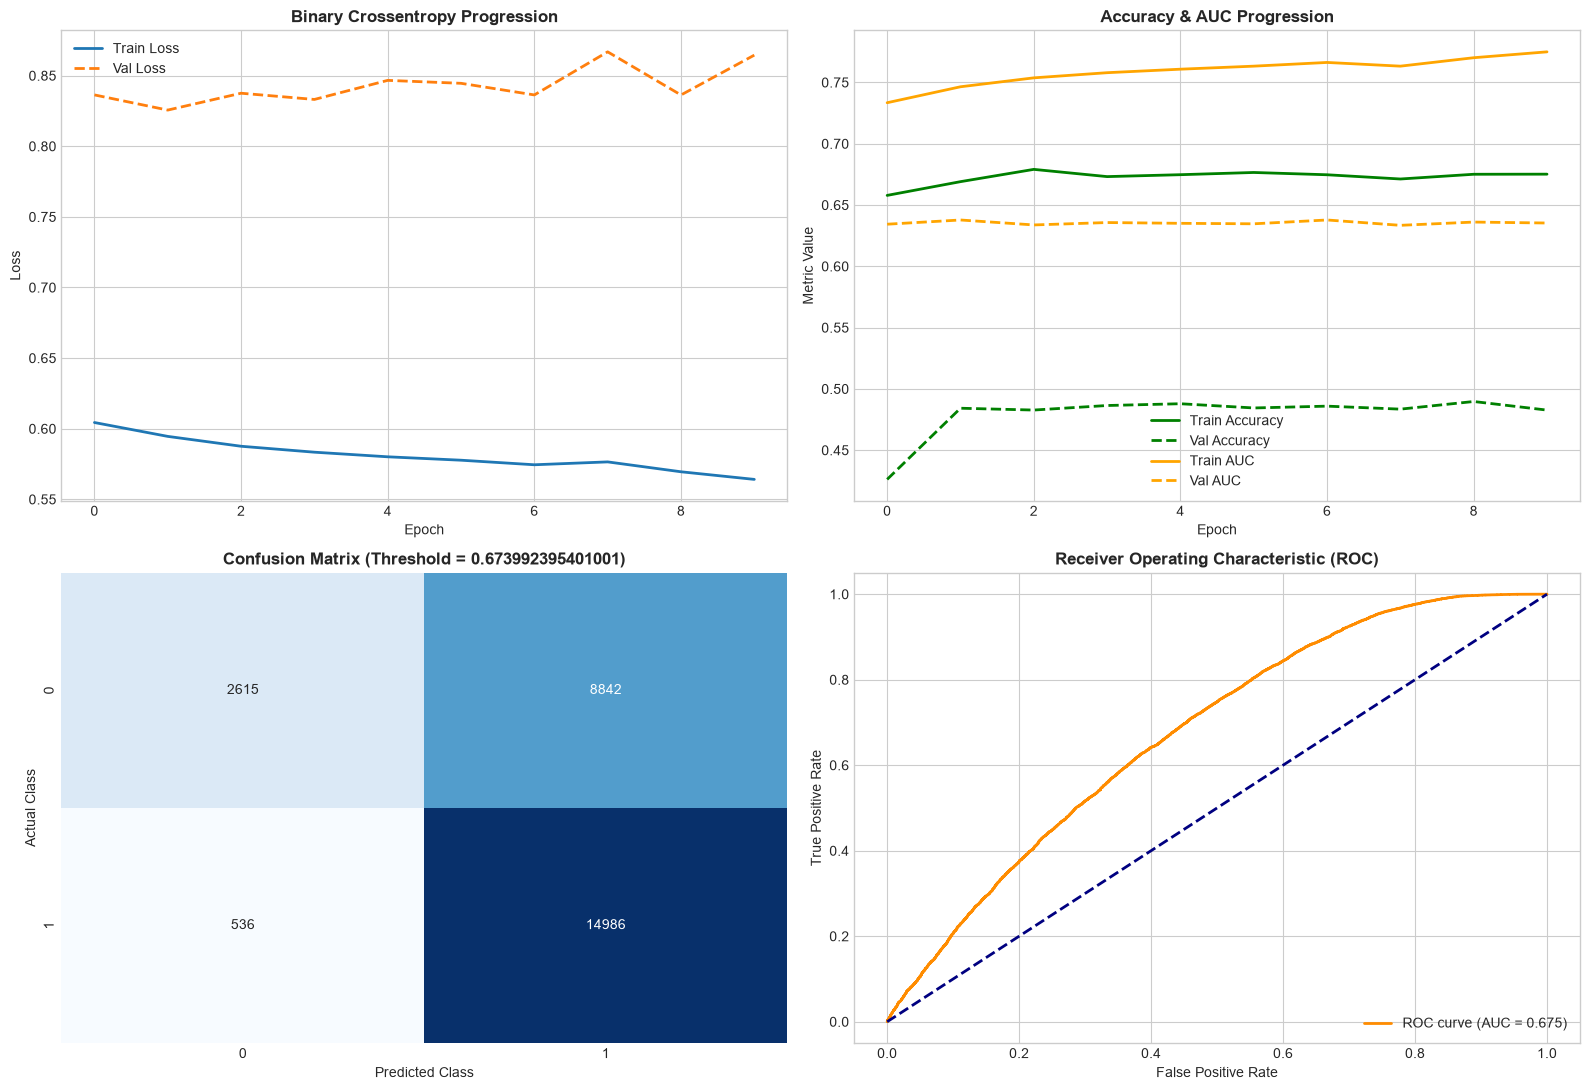


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.650246
Precision 0.626119
   Recall 0.973264
 F1-Score 0.762018
  ROC-AUC 0.675040
   PR-AUC 0.689334


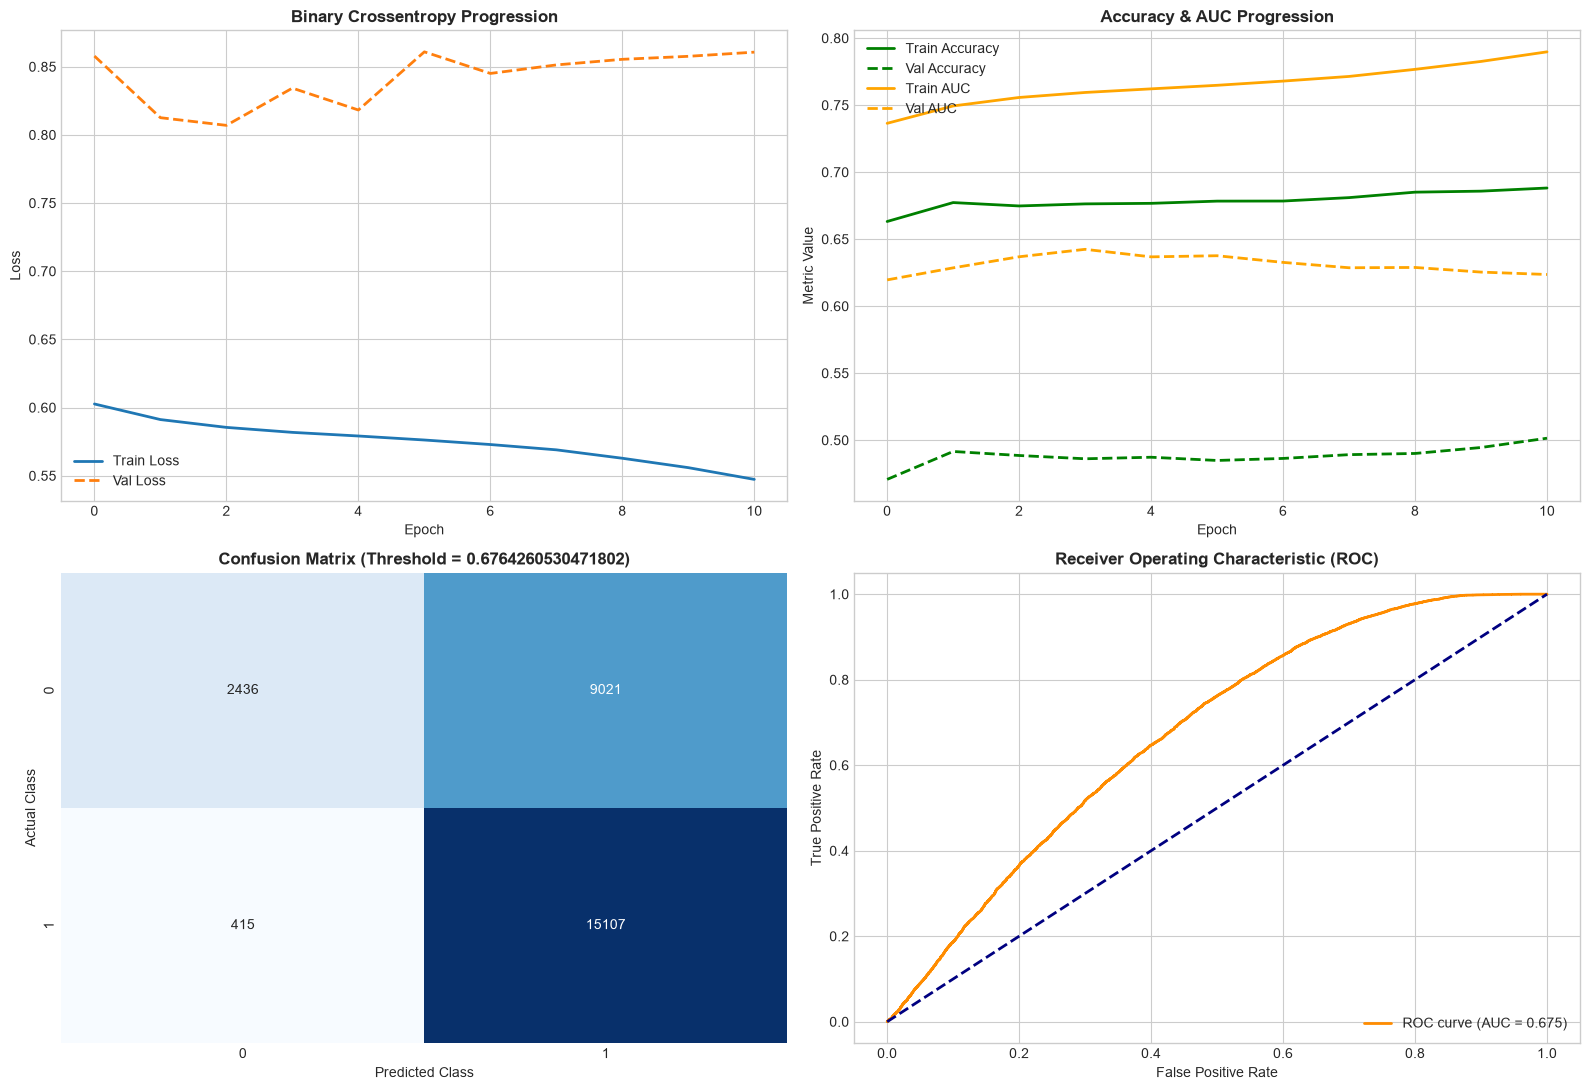


=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.654694
Precision 0.629659
   Recall 0.970816
 F1-Score 0.763877
  ROC-AUC 0.672187
   PR-AUC 0.702130


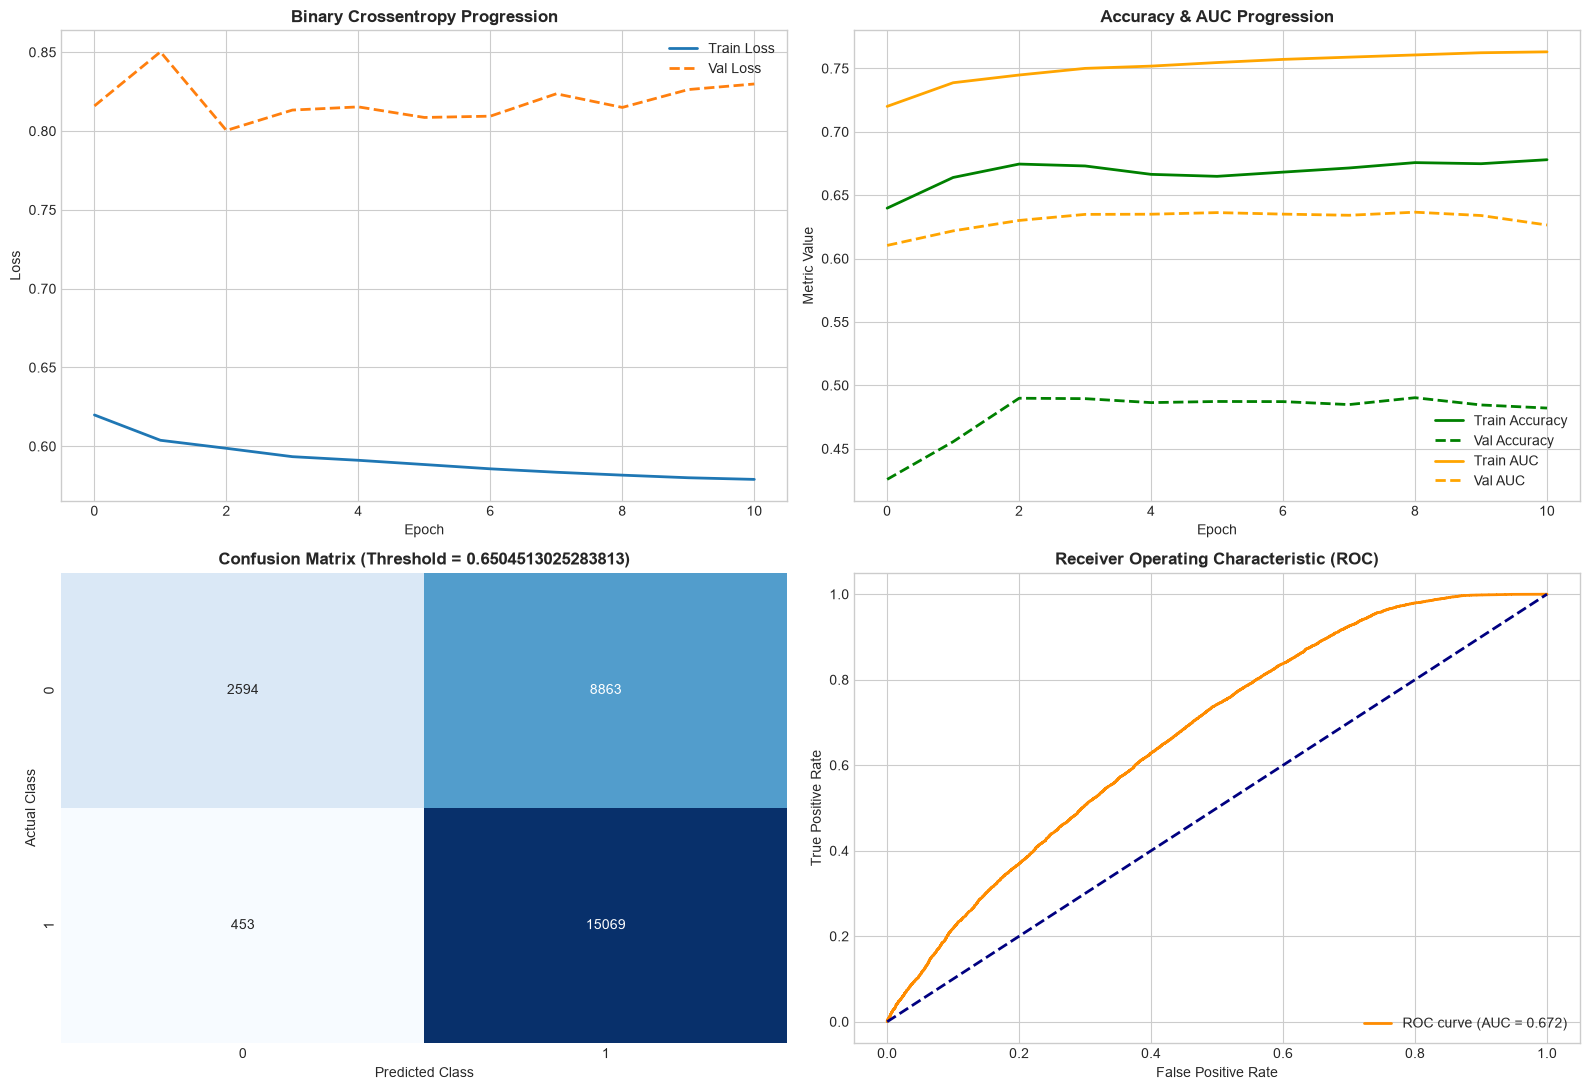

,Architecture,Threshold (validation),Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test PR-AUC
0,base,0.660110,0.634166,0.657474,0.632159,0.967788,0.764770,0.665267,0.684835
1,norm,0.676426,0.631639,0.650246,0.626119,0.973264,0.762018,0.675040,0.689334
2,dense,0.673992,0.630760,0.652396,0.628924,0.965468,0.761677,0.675038,0.700726
3,norm+drop,0.650451,0.630329,0.654694,0.629659,0.970816,0.763877,0.672187,0.702130


Modelo seleccionado por F1 de validación: base (umbral=0.6601, F1 validación=0.6342)


In [43]:
test_comparison = []
predictions_by_architecture = {}
metrics_by_architecture = {}

for architecture, result in training_results.items():
    predictions, metrics = model_base.evaluate(
        model=result["model"],
        history=result["history"],
        X_test=X_test,
        y_test=y_test,
        threshold=result["threshold"],
    )
    predictions_by_architecture[architecture] = predictions
    metrics_by_architecture[architecture] = metrics
    metric_values = dict(zip(metrics["Metric"], metrics["Value"]))
    test_comparison.append(
        {
            "Architecture": architecture,
            "Threshold (validation)": result["threshold"],
            "Validation F1": result["validation_f1"],
            "Test Accuracy": metric_values["Accuracy"],
            "Test Precision": metric_values["Precision"],
            "Test Recall": metric_values["Recall"],
            "Test F1": metric_values["F1-Score"],
            "Test ROC-AUC": metric_values["ROC-AUC"],
            "Test PR-AUC": metric_values["PR-AUC"],
        }
    )

comparison = pd.DataFrame(test_comparison).sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)
best_architecture = max(
    training_results,
    key=lambda name: training_results[name]["validation_f1"],
)
best_model = training_results[best_architecture]["model"]
best_threshold = training_results[best_architecture]["threshold"]
history = training_results[best_architecture]["history"]
model = best_model
df_preds = predictions_by_architecture[best_architecture]
df_metrics = metrics_by_architecture[best_architecture]
best_model_path = model_output_dir / "lstm_model.keras"
best_model_path.parent.mkdir(parents=True, exist_ok=True)
best_model.save(best_model_path)

# Guardar también el preprocesador (necesario para inferencia)
import joblib
joblib.dump(preprocessor, model_output_dir / "preprocessor.joblib")

display(comparison)
print(
    f"Modelo seleccionado por F1 de validación: {best_architecture} "
    f"(umbral={best_threshold:.4f}, "
    f"F1 validación={training_results[best_architecture]['validation_f1']:.4f})"
)

# Baseline de persistencia y métricas por máquina

- **Baseline**: "mañana a esta hora habrá cola si hoy a esta hora hubo cola" (solo aplica en modo `punto` con `HORIZON=48`).
  Si la LSTM no supera este baseline, no está aportando más que la estacionalidad diaria.
- **Métricas por máquina**: un F1 global puede esconder máquinas donde el modelo no funciona.

In [30]:
from sklearn.metrics import precision_score, recall_score, f1_score

prob_test = best_model.predict(X_test, verbose=0).ravel()
pred_test = (prob_test >= best_threshold).astype(int)

res_test = meta_test.copy()
res_test["Actual"] = y_test.astype(int)
res_test["Predicted Class"] = pred_test
res_test["Prob"] = prob_test

if MODO_OBJETIVO == "punto" and HORIZON == 48:
    idx_cola = feature_names.index("cola")
    base_pred = X_test[:, -1, idx_cola].astype(int)   # cola 24 h antes del bloque objetivo
    print("Baseline persistencia 24 h -> P: %.3f | R: %.3f | F1: %.3f" % (
        precision_score(y_test, base_pred, zero_division=0),
        recall_score(y_test, base_pred, zero_division=0),
        f1_score(y_test, base_pred, zero_division=0)))

filas = []
for ms, g in res_test.groupby("ms"):
    filas.append({
        "ms": ms,
        "ventanas": len(g),
        "pct_cola_real": g["Actual"].mean(),
        "Precision": precision_score(g["Actual"], g["Predicted Class"], zero_division=0),
        "Recall": recall_score(g["Actual"], g["Predicted Class"], zero_division=0),
        "F1": f1_score(g["Actual"], g["Predicted Class"], zero_division=0),
    })
metricas_por_maquina = pd.DataFrame(filas).sort_values("F1", ascending=False).reset_index(drop=True)
display(metricas_por_maquina)

Baseline persistencia 24 h -> P: 0.650 | R: 0.649 | F1: 0.650


,ms,ventanas,pct_cola_real,Precision,Recall,F1
0,VMS 1,8993,0.630713,0.686297,0.961566,0.800940
1,VMS 2,8993,0.567441,0.625692,0.974525,0.762087
2,VMS 3,8993,0.527855,0.584011,0.967980,0.728498


# Rachas continuas de cola (real vs predicho), medidas por máquina

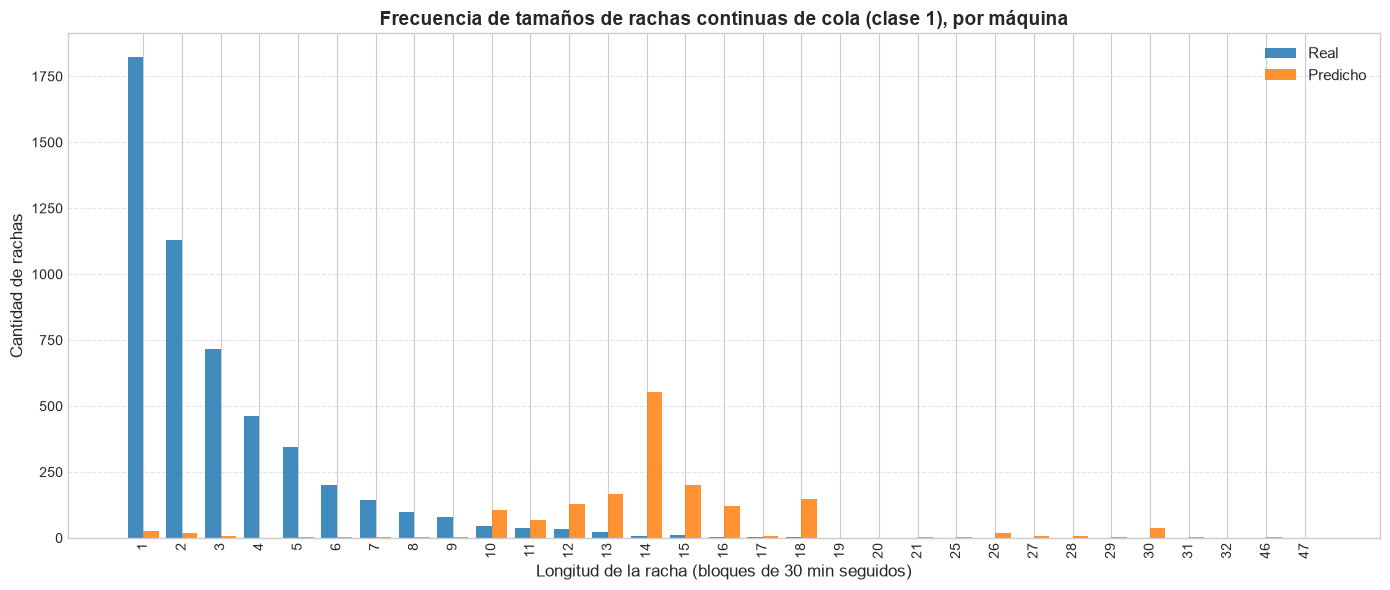

In [31]:
import matplotlib.pyplot as plt

def longitudes_rachas(res, col, clase=1, freq=FREQ):
    """Longitud de rachas consecutivas de `clase`, calculadas dentro de cada máquina
    y cortando la racha si hay un salto de tiempo distinto a `freq`."""
    paso = pd.Timedelta(freq)
    largos = []
    for ms, g in res.groupby("ms"):
        g = g.sort_values("bloque_tiempo")
        s = g[col].values
        t = g["bloque_tiempo"].values
        cambia = np.r_[True, (s[1:] != s[:-1]) | (np.diff(t) != np.timedelta64(paso))]
        grupo = np.cumsum(cambia)
        tmp = pd.DataFrame({"g": grupo, "v": s})
        largos.extend(tmp.groupby("g")["v"].agg(lambda x: len(x) if x.iloc[0] == clase else 0).tolist())
    largos = pd.Series(largos)
    return largos[largos > 0]

freq_reales = longitudes_rachas(res_test, "Actual").value_counts()
freq_predichos = longitudes_rachas(res_test, "Predicted Class").value_counts()

df_histograma = pd.DataFrame({
    "Real": freq_reales,
    "Predicho": freq_predichos
}).fillna(0).sort_index()

plt.figure(figsize=(14, 6))
ancho_barra = 0.4
x = np.arange(len(df_histograma))

plt.bar(x - ancho_barra/2, df_histograma["Real"], width=ancho_barra, label="Real", color="#1f77b4", alpha=0.85)
plt.bar(x + ancho_barra/2, df_histograma["Predicho"], width=ancho_barra, label="Predicho", color="#ff7f0e", alpha=0.85)

plt.title("Frecuencia de tamaños de rachas continuas de cola (clase 1), por máquina", fontsize=14, fontweight="bold")
plt.xlabel("Longitud de la racha (bloques de 30 min seguidos)", fontsize=12)
plt.ylabel("Cantidad de rachas", fontsize=12)
plt.xticks(x, labels=[str(int(i)) for i in df_histograma.index], rotation=90 if len(df_histograma) > 20 else 0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Día 1 - Historial: 2025-12-30
Día 2 - Evaluación: 2025-12-31
Día 3 - Predicción futura: 2026-01-01
Último día disponible: 2025-12-31

Procesando máquina VMS 1...


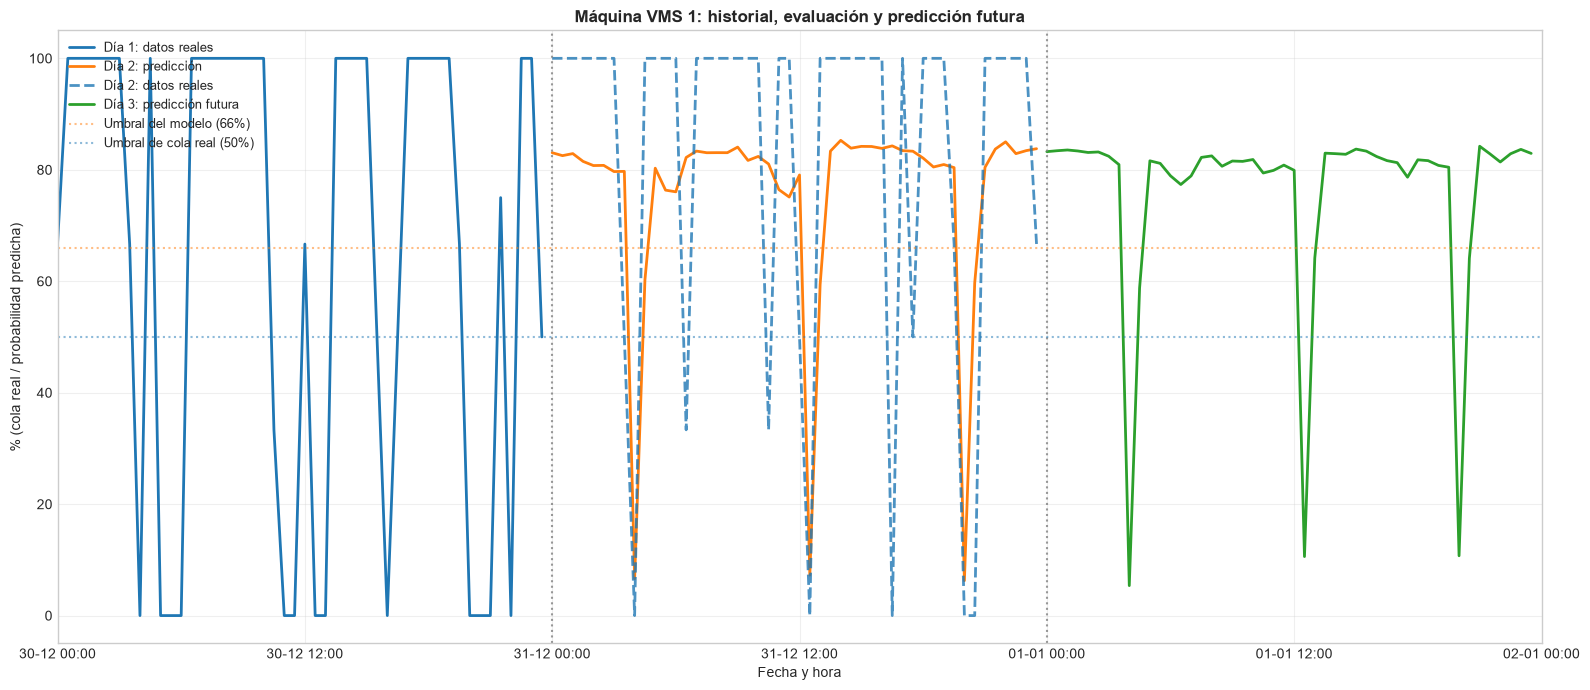


Procesando máquina VMS 2...


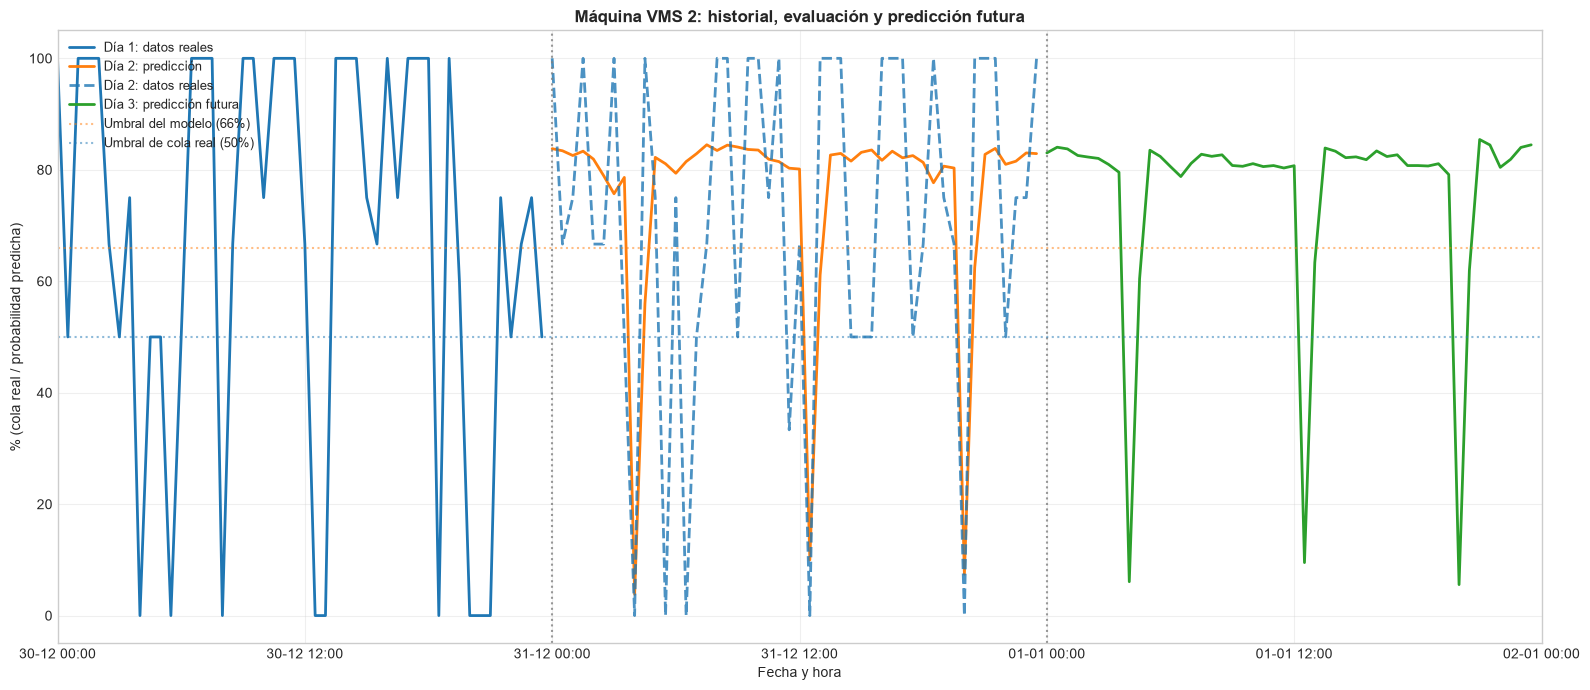


Procesando máquina VMS 3...


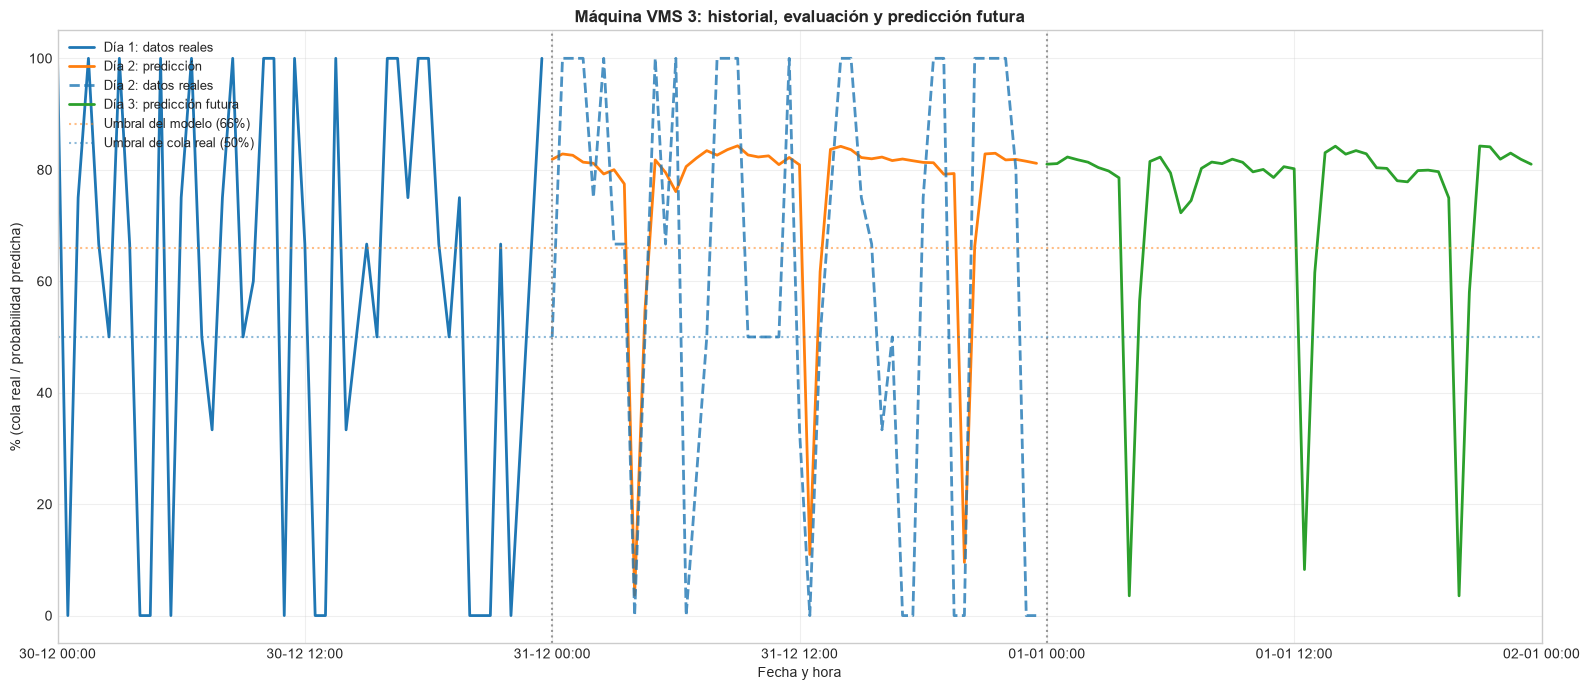

In [32]:

import matplotlib.dates as mdates

if MODO_OBJETIVO != "punto":
    raise ValueError(
        "Esta visualización requiere MODO_OBJETIVO = 'punto' "
        "(una predicción por bloque)."
    )

# ============================================================
# 1. PARÁMETROS
# ============================================================

FECHA_ORIGEN = None  # None = penúltimo día disponible
DIAS_HISTORIA = 1
MAQUINAS = None
MAX_MAQUINAS = 6

paso = pd.Timedelta(FREQ)

# Último día con datos reales
ultimo_dia = pd.Timestamp(tiempos.max()).normalize()

# Día 1: historial
dia_origen = (
    pd.Timestamp(FECHA_ORIGEN).normalize()
    if FECHA_ORIGEN
    else ultimo_dia - pd.Timedelta(days=1)
)

# Día 2: predicción que podemos comparar con datos reales
dia_sig = dia_origen + pd.Timedelta(days=1)

# Día 3: predicción futura sin datos reales
dia_fin = dia_sig + pd.Timedelta(days=1)

# Límite exclusivo de la visualización
dia_despues = dia_fin + pd.Timedelta(days=1)

ini_hist = dia_origen - pd.Timedelta(days=DIAS_HISTORIA - 1)

print(f"Día 1 - Historial: {dia_origen.date()}")
print(f"Día 2 - Evaluación: {dia_sig.date()}")
print(f"Día 3 - Predicción futura: {dia_fin.date()}")
print(f"Último día disponible: {ultimo_dia.date()}")

if dia_sig > ultimo_dia:
    raise ValueError(
        "No hay datos reales suficientes para evaluar el día 2."
    )

if dia_fin <= ultimo_dia:
    print(
        "Aviso: el día 3 también tiene datos reales disponibles."
    )


# ============================================================
# 2. ÍNDICES Y DATOS REALES
# ============================================================

idx_por_ms = meta.groupby("ms").indices


def datos_reales(ms):
    idx = np.sort(idx_por_ms[ms])

    return pd.DataFrame({
        "bloque_tiempo": meta["bloque_tiempo"].values[idx],
        "pct": full[TARGET].values[idx],
        "cola": y_full[idx],
    })


reales = {
    ms: datos_reales(ms)
    for ms in idx_por_ms
}


# ============================================================
# 3. FUNCIÓN DE PREDICCIÓN
# ============================================================

def predecir_dia_siguiente(ms, dia_objetivo):
    """
    Predice cada bloque de un día específico.

    Cada ventana termina HORIZON bloques antes del objetivo.
    Utiliza X_all, que contiene las ventanas históricas originales.
    """

    idx = np.sort(idx_por_ms[ms])

    pos = pd.Series(
        np.arange(len(idx)),
        index=pd.DatetimeIndex(
            meta["bloque_tiempo"].values[idx]
        )
    )

    fin_dia = dia_objetivo + pd.Timedelta(days=1)

    objetivos = pd.date_range(
        dia_objetivo,
        fin_dia - paso,
        freq=FREQ
    )

    ventanas = []
    tiempos_obj = []

    for tgt in objetivos:

        fin = tgt - HORIZON * paso
        p_fin = pos.get(fin)

        if p_fin is None or p_fin - WINDOW + 1 < 0:
            continue

        ventanas.append(
            X_all[
                idx[p_fin - WINDOW + 1:p_fin + 1]
            ]
        )

        tiempos_obj.append(tgt)

    if not ventanas:
        return None

    prob = best_model.predict(
        np.stack(ventanas),
        verbose=0
    ).ravel()

    return pd.DataFrame({
        "bloque_tiempo": tiempos_obj,
        "prob": prob
    })


# ============================================================
# 4. SELECCIÓN DE MÁQUINAS
# ============================================================

if MAQUINAS is None:

    def cola_total(ms):
        d = reales[ms]

        d = d[
            (d.bloque_tiempo >= ini_hist) &
            (d.bloque_tiempo < dia_fin)
        ]

        return np.nansum(d["cola"].values)

    MAQUINAS = sorted(
        reales,
        key=cola_total,
        reverse=True
    )[:MAX_MAQUINAS]


# ============================================================
# 5. PREDICCIONES, TABLAS Y GRÁFICAS
# ============================================================

tablas_horarias = {}

for ms in MAQUINAS:

    print(f"\nProcesando máquina {ms}...")

    # --------------------------------------------------------
    # Predicciones de los días 2 y 3
    # --------------------------------------------------------

    pred_dia2 = predecir_dia_siguiente(
        ms,
        dia_sig
    )

    pred_dia3 = predecir_dia_siguiente(
        ms,
        dia_fin
    )

    if pred_dia2 is None:
        print(
            f"Máquina {ms}: no hay historial suficiente "
            f"para predecir el día 2."
        )
        continue

    if pred_dia3 is None:
        print(
            f"Máquina {ms}: no hay historial suficiente "
            f"para predecir el día 3."
        )
        continue

    # --------------------------------------------------------
    # Datos reales
    # --------------------------------------------------------

    real = reales[ms]

    # Día 1: historial
    hist = real[
        (real.bloque_tiempo >= ini_hist) &
        (real.bloque_tiempo < dia_sig)
    ]

    # Día 2: datos reales para comparación
    real_dia2 = real[
        (real.bloque_tiempo >= dia_sig) &
        (real.bloque_tiempo < dia_fin)
    ]

    # Día 3: no se utilizan datos reales
    # --------------------------------------------------------

    # --------------------------------------------------------
    # Tabla horaria del día 2 y día 3
    # --------------------------------------------------------

    tab_dia2 = (
        pred_dia2.assign(
            hora=pred_dia2.bloque_tiempo.dt.hour
        )
        .groupby("hora")
        .agg(
            prob_cola_pred=(
                "prob",
                "mean"
            ),
            pct_bloques_pred_cola=(
                "prob",
                lambda p: (p >= best_threshold).mean()
            ),
        )
    )

    # Agregar valores reales del día 2
    if len(real_dia2):

        real_h = (
            real_dia2.assign(
                hora=real_dia2.bloque_tiempo.dt.hour
            )
            .groupby("hora")
            .agg(
                pct_bloques_real_cola=(
                    "cola",
                    "mean"
                ),
                pct_posible_cola_real=(
                    "pct",
                    "mean"
                ),
            )
        )

        tab_dia2 = tab_dia2.join(real_h)

    # Tabla del día 3
    tab_dia3 = (
        pred_dia3.assign(
            hora=pred_dia3.bloque_tiempo.dt.hour
        )
        .groupby("hora")
        .agg(
            prob_cola_pred=(
                "prob",
                "mean"
            ),
            pct_bloques_pred_cola=(
                "prob",
                lambda p: (p >= best_threshold).mean()
            ),
        )
    )

    tablas_horarias[ms] = {
        "dia2": tab_dia2,
        "dia3": tab_dia3
    }

    # ========================================================
    # 6. GRÁFICA PRINCIPAL
    # ========================================================

    fig, ax1 = plt.subplots(
        figsize=(16, 7)
    )

    # Día 1: datos históricos
    ax1.plot(
        hist.bloque_tiempo,
        hist.pct * 100,
        color="#1f77b4",
        lw=2,
        label="Día 1: datos reales"
    )

    # Día 2: predicción
    ax1.plot(
        pred_dia2.bloque_tiempo,
        pred_dia2.prob * 100,
        color="#ff7f0e",
        lw=2,
        label="Día 2: predicción"
    )

    # Día 2: datos reales
    if len(real_dia2):

        ax1.plot(
            real_dia2.bloque_tiempo,
            real_dia2.pct * 100,
            color="#1f77b4",
            ls="--",
            lw=2,
            alpha=0.8,
            label="Día 2: datos reales"
        )

    # Día 3: predicción futura
    ax1.plot(
        pred_dia3.bloque_tiempo,
        pred_dia3.prob * 100,
        color="#2ca02c",
        lw=2,
        label="Día 3: predicción futura"
    )

    # Separadores entre días
    ax1.axvline(
        dia_sig,
        color="gray",
        ls=":",
        alpha=0.8
    )

    ax1.axvline(
        dia_fin,
        color="gray",
        ls=":",
        alpha=0.8
    )

    # Umbral de clasificación
    ax1.axhline(
        best_threshold * 100,
        color="#ff7f0e",
        ls=":",
        alpha=0.5,
        label=(
            f"Umbral del modelo "
            f"({best_threshold * 100:.0f}%)"
        )
    )

    # Umbral de cola real
    ax1.axhline(
        UMBRAL_COLA * 100,
        color="#1f77b4",
        ls=":",
        alpha=0.5,
        label=(
            f"Umbral de cola real "
            f"({UMBRAL_COLA * 100:.0f}%)"
        )
    )

    ax1.set_title(
        f"Máquina {ms}: historial, evaluación "
        f"y predicción futura",
        fontweight="bold"
    )

    ax1.set_ylabel(
        "% (cola real / probabilidad predicha)"
    )

    ax1.set_xlabel("Fecha y hora")

    ax1.xaxis.set_major_formatter(
        mdates.DateFormatter("%d-%m %H:%M")
    )

    ax1.set_xlim(
        ini_hist,
        dia_despues
    )

    ax1.grid(alpha=0.3)
    ax1.legend(
        loc="upper left",
        fontsize=9
    )

    plt.tight_layout()
    plt.show()

    # ========================================================
    # 7. TABLAS HORARIAS
    # ========================================================

    # print(
    #     f"\nMáquina {ms} - "
    #     f"Comparación horaria del día 2 ({dia_sig.date()})"
    # )

    # display(
    #     tab_dia2.round(3)
    # )

    # print(
    #     f"\nMáquina {ms} - "
    #     f"Predicción horaria del día 3 ({dia_fin.date()})"
    # )

    # display(
    #     tab_dia3.round(3)
    # )
